# Week 5 — Robustness, sensitivity and performance

This notebook investigates whether the D7 PCHIP/30-minute recommendation
remains defensible across elephants, starting offsets and alternative
acceptance tolerances.

The notebook also records the personal robustness decision D8. Code
profiling and optimisation decisions are completed after these results
have been inspected.

In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

current_folder = Path.cwd()

if (current_folder / "reports").exists():
    PROJECT_FOLDER = current_folder
elif (current_folder.parent / "reports").exists():
    PROJECT_FOLDER = current_folder.parent
else:
    raise FileNotFoundError(
        "Cannot find the project folder."
    )

REPORTS_FOLDER = PROJECT_FOLDER / "reports"
FIGURES_FOLDER = PROJECT_FOLDER / "figures"

FIGURES_FOLDER.mkdir(exist_ok=True)

if str(PROJECT_FOLDER) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_FOLDER),
    )

from src import robustness

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

print("Python:", sys.executable)
print("Project:", PROJECT_FOLDER)

Python: c:\Users\kookie\OneDrive\MMA3001_project\.venv\Scripts\python.exe
Project: c:\Users\kookie\OneDrive\MMA3001_project


In [ ]:
validation_summary = pd.read_csv(
    REPORTS_FOLDER
    / "week4_validation_summary.csv"
)

per_animal = pd.read_csv(
    REPORTS_FOLDER
    / "week4_per_animal_summary.csv"
)

offset_summary = pd.read_csv(
    REPORTS_FOLDER
    / "week4_offset_summary.csv"
)

case_results = pd.read_csv(
    REPORTS_FOLDER
    / "week4_case_results.csv"
)

sensitivity = pd.read_csv(
    REPORTS_FOLDER
    / "week5_tolerance_sensitivity.csv"
)

with (
    REPORTS_FOLDER
    / "week4_final_decision.yaml"
).open(
    "r",
    encoding="utf-8",
) as stream:
    final_decision = yaml.safe_load(stream)

SELECTED_METHOD = final_decision[
    "selected_method"
]

SELECTED_INTERVAL_MIN = int(
    final_decision[
        "selected_interval_minutes"
    ]
)

print("D7 method:", SELECTED_METHOD)
print(
    "D7 interval:",
    SELECTED_INTERVAL_MIN,
    "minutes",
)

display(validation_summary)

D7 method: pchip
D7 interval: 30 minutes


,Method,Interval_min,PredictedFixes,MedianPositionError_m,MAE_m,RMSE_m,P95PositionError_m,MaximumPositionError_m,MedianResidualX_m,MedianResidualY_m,OvershootCount,OvershootPercent,TotalCases,SuccessfulCases,MedianSignedPathError_percent,MedianAbsolutePathError_percent,P95AbsolutePathError_percent,MedianFixReduction_percent,TotalInterpolationRuntime_s,MaximumReconstructedSpeed_mps,FailedCases,CaseSuccessPercent,PositionCriterionPass,PathCriterionPass,MandatoryCriteriaPass,AvailableCases,MethodSupportedCases,MethodUsableWithheld,CaseCoverage_percent
0,linear,30,59833,40.785703,58.570684,87.377769,166.766850,2307.960941,0.000000e+00,0.000000e+00,0,0.000000,146,146,-8.180282,8.180282,11.764959,49.894067,0.016132,1.652908,0,100.0,True,True,True,154,150,59840,97.402597
1,cubic,30,59833,42.614796,59.161588,86.767613,160.255845,2310.585689,-3.958414e-02,1.073016e-02,19563,32.696004,146,146,-5.274624,5.274624,8.647055,49.894067,0.094317,1.688870,0,100.0,True,True,True,154,146,59833,94.805195
2,pchip,30,59833,39.631957,56.444618,84.317611,158.135324,2309.816682,-3.728928e-10,0.000000e+00,0,0.000000,146,146,-7.906592,7.906592,11.487874,49.894067,0.104677,1.666694,0,100.0,True,True,True,154,150,59840,97.402597
3,linear,60,179061,65.465590,93.202903,134.337534,266.821478,2311.210430,3.747118e-10,2.779873e-01,0,0.000000,292,292,-15.774207,15.774207,20.259679,74.840085,0.033674,1.379704,0,100.0,True,False,False,308,295,179070,95.779221
4,cubic,60,179061,66.822203,92.525805,130.661834,254.984627,2322.376056,-1.287053e-01,8.023108e-03,60093,33.560072,292,292,-11.803706,11.803706,16.285875,74.840085,0.177079,1.468499,0,100.0,True,False,False,308,292,179061,94.805195
5,pchip,60,179061,61.487702,88.588363,128.929675,255.565996,2308.359785,9.654480e-03,1.082830e-01,0,0.000000,292,292,-15.167983,15.167983,19.677091,74.840085,0.198853,1.717950,0,100.0,True,False,False,308,295,179070,95.779221
6,linear,120,415695,114.255510,162.232485,230.551316,466.480139,3139.565720,9.200302e-01,-5.093170e-11,0,0.000000,576,576,-23.375102,23.375102,30.498419,87.319477,0.067820,1.242465,0,100.0,False,False,False,616,584,415765,94.805195
7,cubic,120,415695,114.122681,158.951432,222.196937,444.349140,3576.749526,5.349548e-02,1.684337e-01,144218,34.693225,576,576,-18.779015,18.779015,26.317920,87.319477,0.348222,1.359322,0,100.0,False,False,False,616,576,415695,93.506494
8,pchip,120,415695,105.190485,152.626019,220.158797,446.516044,3813.770661,3.559618e-01,7.926982e-02,0,0.000000,576,576,-22.582046,22.582046,29.835225,87.319477,0.378593,1.504683,0,100.0,False,False,False,616,584,415765,94.805195
9,linear,240,881340,216.087827,301.302165,419.165661,849.686436,5008.777790,2.825807e+00,-1.556729e+00,0,0.000000,1124,1124,-32.025415,32.025415,42.028076,93.561368,0.126441,0.997886,0,100.0,False,False,False,1232,1154,882165,93.668831


In [ ]:
selected_summary = validation_summary.loc[
    validation_summary["Method"].eq(
        SELECTED_METHOD
    )
    & validation_summary[
        "Interval_min"
    ].eq(
        SELECTED_INTERVAL_MIN
    )
].copy()

assert len(selected_summary) == 1

display(selected_summary)

selected_row = selected_summary.iloc[0]

assert (
    selected_row["MedianPositionError_m"]
    <= 100
)

assert (
    selected_row[
        "MedianAbsolutePathError_percent"
    ]
    <= 10
)

print(
    "Frozen D7 result still passes:",
    SELECTED_METHOD,
    SELECTED_INTERVAL_MIN,
)

,Method,Interval_min,PredictedFixes,MedianPositionError_m,MAE_m,RMSE_m,P95PositionError_m,MaximumPositionError_m,MedianResidualX_m,MedianResidualY_m,OvershootCount,OvershootPercent,TotalCases,SuccessfulCases,MedianSignedPathError_percent,MedianAbsolutePathError_percent,P95AbsolutePathError_percent,MedianFixReduction_percent,TotalInterpolationRuntime_s,MaximumReconstructedSpeed_mps,FailedCases,CaseSuccessPercent,PositionCriterionPass,PathCriterionPass,MandatoryCriteriaPass,AvailableCases,MethodSupportedCases,MethodUsableWithheld,CaseCoverage_percent
2,pchip,30,59833,39.631957,56.444618,84.317611,158.135324,2309.816682,-3.728928e-10,0.0,0,0.0,146,146,-7.906592,7.906592,11.487874,49.894067,0.104677,1.666694,0,100.0,True,True,True,154,150,59840,97.402597


Frozen D7 result still passes: pchip 30


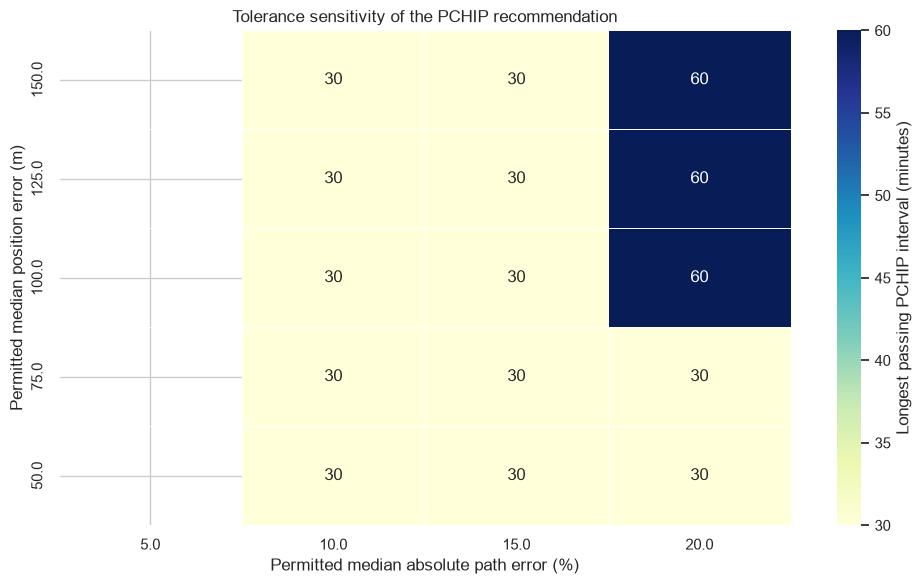

Saved: c:\Users\kookie\OneDrive\MMA3001_project\figures\week5_01_tolerance_sensitivity.png


In [ ]:
selected_sensitivity = sensitivity.copy()

sensitivity_grid = (
    selected_sensitivity.pivot(
        index="PositionTolerance_m",
        columns="PathTolerance_percent",
        values=(
            "LongestPassingInterval_"
            "selected_method_min"
        ),
    )
    .sort_index(ascending=False)
    .sort_index(axis=1)
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    sensitivity_grid,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": (
            "Longest passing PCHIP "
            "interval (minutes)"
        )
    },
)

plt.title(
    "Tolerance sensitivity of the "
    "PCHIP recommendation"
)
plt.xlabel(
    "Permitted median absolute "
    "path error (%)"
)
plt.ylabel(
    "Permitted median position "
    "error (m)"
)

plt.tight_layout()

tolerance_figure = (
    FIGURES_FOLDER
    / "week5_01_tolerance_sensitivity.png"
)

plt.savefig(
    tolerance_figure,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved:", tolerance_figure)

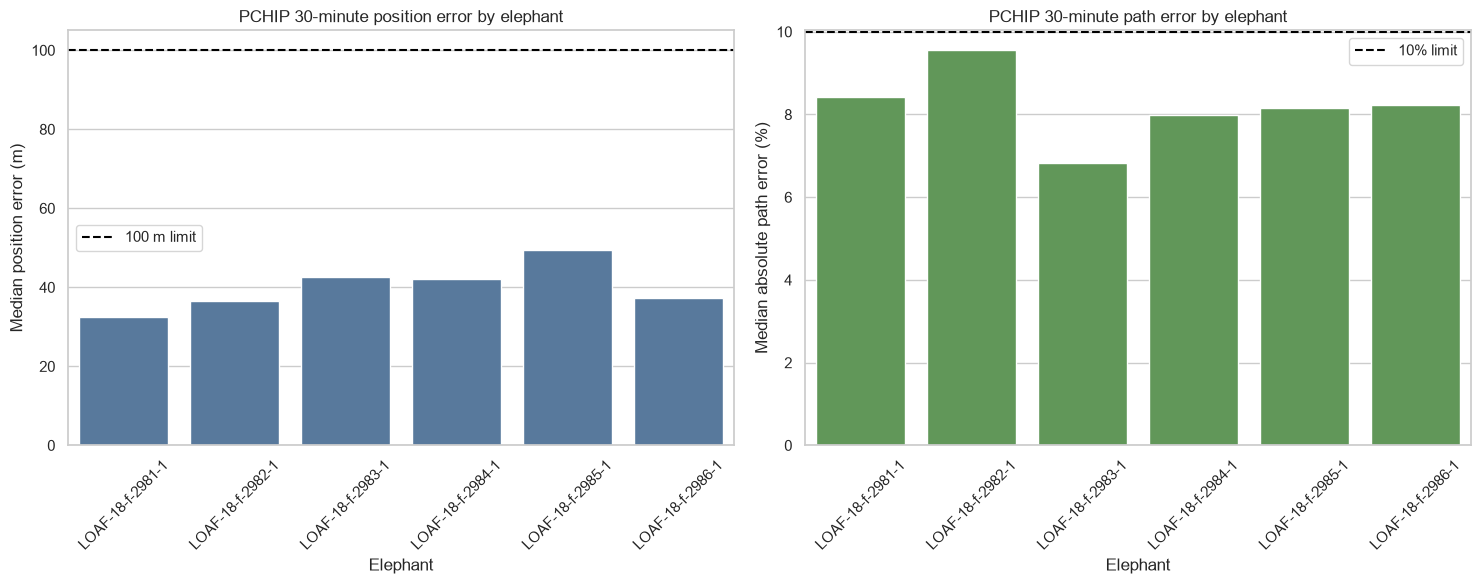

Saved: c:\Users\kookie\OneDrive\MMA3001_project\figures\week5_02_selected_method_by_animal.png


In [ ]:
selected_animal = per_animal.loc[
    per_animal["Method"].eq(
        SELECTED_METHOD
    )
    & per_animal["Interval_min"].eq(
        SELECTED_INTERVAL_MIN
    )
].copy()

selected_animal = selected_animal.sort_values(
    "AnimalID"
)

assert selected_animal[
    "AnimalID"
].nunique() == 6

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6),
)

sns.barplot(
    data=selected_animal,
    x="AnimalID",
    y="MedianPositionError_m",
    color="#4C78A8",
    ax=axes[0],
)

axes[0].axhline(
    100,
    color="black",
    linestyle="--",
    label="100 m limit",
)

axes[0].set_title(
    "PCHIP 30-minute position error "
    "by elephant"
)
axes[0].set_xlabel("Elephant")
axes[0].set_ylabel(
    "Median position error (m)"
)
axes[0].tick_params(
    axis="x",
    rotation=45,
)
axes[0].legend()

sns.barplot(
    data=selected_animal,
    x="AnimalID",
    y=(
        "MedianAbsolutePathError_"
        "percent"
    ),
    color="#59A14F",
    ax=axes[1],
)

axes[1].axhline(
    10,
    color="black",
    linestyle="--",
    label="10% limit",
)

axes[1].set_title(
    "PCHIP 30-minute path error "
    "by elephant"
)
axes[1].set_xlabel("Elephant")
axes[1].set_ylabel(
    "Median absolute path error (%)"
)
axes[1].tick_params(
    axis="x",
    rotation=45,
)
axes[1].legend()

plt.tight_layout()

animal_figure = (
    FIGURES_FOLDER
    / "week5_02_selected_method_by_animal.png"
)

plt.savefig(
    animal_figure,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved:", animal_figure)

,Method,Interval_min,Offset,PredictedFixes,MedianPositionError_m,MAE_m,RMSE_m,P95PositionError_m,MaximumPositionError_m,MedianResidualX_m,MedianResidualY_m,OvershootCount,OvershootPercent,TotalCases,SuccessfulCases,MedianSignedPathError_percent,MedianAbsolutePathError_percent,P95AbsolutePathError_percent,MedianFixReduction_percent,TotalInterpolationRuntime_s,MaximumReconstructedSpeed_mps,FailedCases,CaseSuccessPercent,PositionCriterionPass,PathCriterionPass,MandatoryCriteriaPass
4,pchip,30,0,29938,39.616610,56.467456,84.999854,158.120962,2309.816682,-0.265919,-0.050358,0,0.0,73,73,-7.979057,7.979057,11.525386,49.894292,0.052905,1.666694,0,100.0,True,True,True
5,pchip,30,1,29895,39.654181,56.421747,83.628809,158.134351,1318.142459,0.085462,0.085298,0,0.0,73,73,-7.887496,7.887496,11.222252,49.893843,0.051772,1.654581,0,100.0,True,True,True


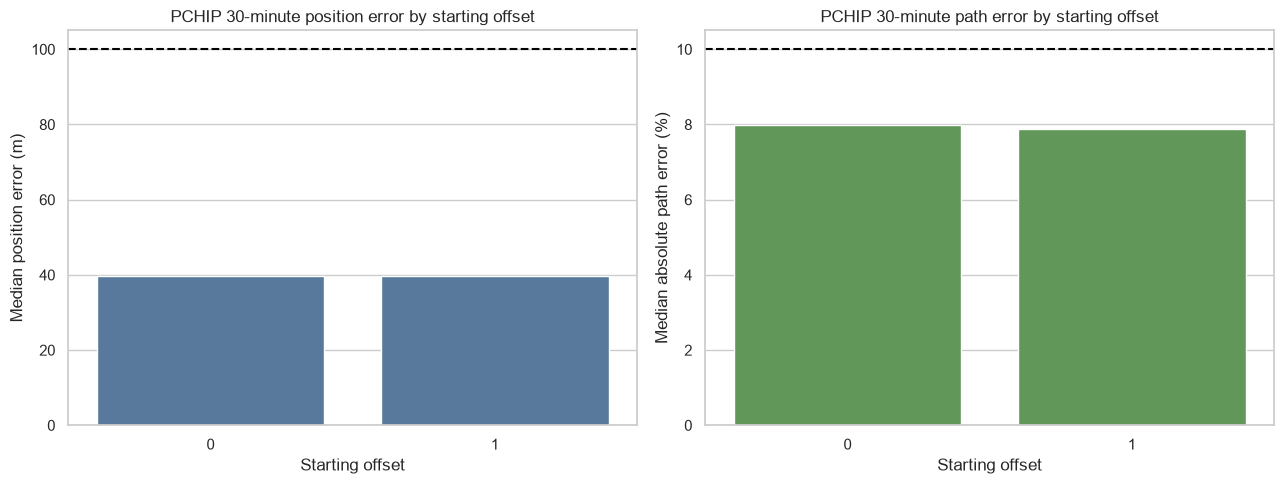

Saved: c:\Users\kookie\OneDrive\MMA3001_project\figures\week5_03_selected_method_by_offset.png


In [ ]:
selected_offset = offset_summary.loc[
    offset_summary["Method"].eq(
        SELECTED_METHOD
    )
    & offset_summary["Interval_min"].eq(
        SELECTED_INTERVAL_MIN
    )
].copy()

display(selected_offset)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
)

sns.barplot(
    data=selected_offset,
    x="Offset",
    y="MedianPositionError_m",
    color="#4C78A8",
    ax=axes[0],
)

axes[0].axhline(
    100,
    color="black",
    linestyle="--",
)

axes[0].set_title(
    "PCHIP 30-minute position error "
    "by starting offset"
)
axes[0].set_xlabel(
    "Starting offset"
)
axes[0].set_ylabel(
    "Median position error (m)"
)

sns.barplot(
    data=selected_offset,
    x="Offset",
    y=(
        "MedianAbsolutePathError_"
        "percent"
    ),
    color="#59A14F",
    ax=axes[1],
)

axes[1].axhline(
    10,
    color="black",
    linestyle="--",
)

axes[1].set_title(
    "PCHIP 30-minute path error "
    "by starting offset"
)
axes[1].set_xlabel(
    "Starting offset"
)
axes[1].set_ylabel(
    "Median absolute path error (%)"
)

plt.tight_layout()

offset_figure = (
    FIGURES_FOLDER
    / "week5_03_selected_method_by_offset.png"
)

plt.savefig(
    offset_figure,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved:", offset_figure)

,Method,Interval_min,Offset,SegmentFixes,RetainedAnchors,EligibleWithheld,MedianError_m,P95Error_m,MaxError_m,AbsolutePathLengthError_percent,CoordinateOvershootCount
398,pchip,30,0,18,9,8,94.511626,243.852338,290.084244,6.276094,0
340,pchip,30,0,64,32,31,71.042713,236.081911,333.672665,8.857291,0
432,pchip,30,0,2481,1241,1240,39.927549,224.983889,912.371648,9.876304,0
417,pchip,30,1,580,290,289,67.282135,214.807548,395.765612,7.705523,0
416,pchip,30,0,580,290,289,60.440977,207.254110,383.964118,7.819810,0
433,pchip,30,1,2481,1240,1239,40.780464,206.047678,980.666919,13.093900,0
429,pchip,30,1,97,48,47,46.989006,205.482121,254.104559,3.959634,0
358,pchip,30,0,83,42,41,62.420730,204.017104,263.646258,4.203265,0
361,pchip,30,1,246,123,122,51.665422,203.037306,1164.257174,7.052206,0
363,pchip,30,1,1464,732,731,48.844178,193.989972,482.473023,5.220108,0


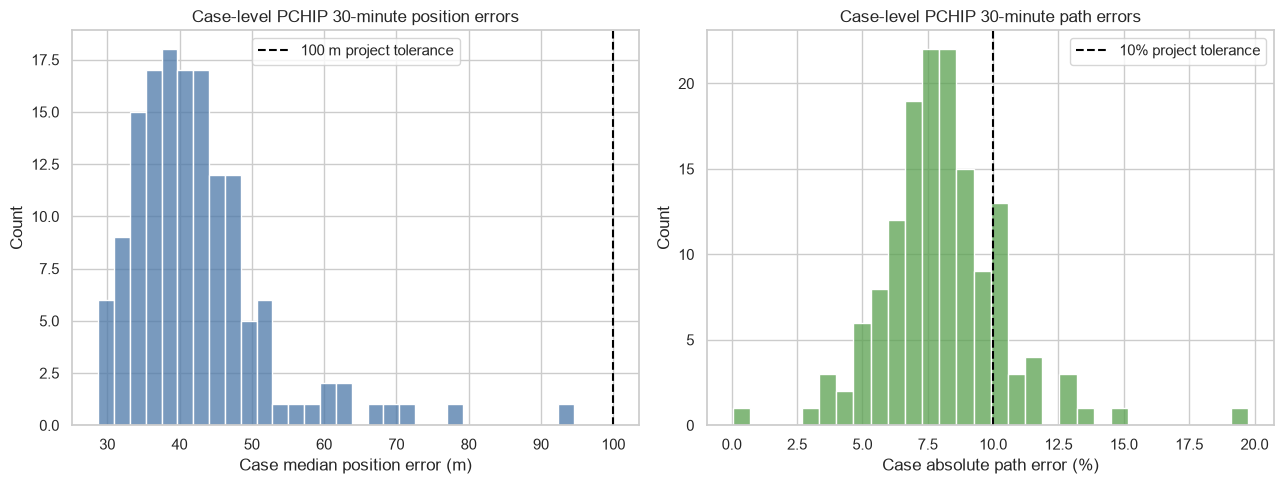

Selected cases: 146
Saved: c:\Users\kookie\OneDrive\MMA3001_project\figures\week5_04_selected_failure_distributions.png


In [ ]:
selected_cases = case_results.loc[
    case_results["Method"].eq(
        SELECTED_METHOD
    )
    & case_results["Interval_min"].eq(
        SELECTED_INTERVAL_MIN
    )
].copy()

worst_selected_cases = (
    selected_cases.sort_values(
        "P95Error_m",
        ascending=False,
    )
    .head(10)
)

display(
    worst_selected_cases[
        [
            "Method",
            "Interval_min",
            "Offset",
            "SegmentFixes",
            "RetainedAnchors",
            "EligibleWithheld",
            "MedianError_m",
            "P95Error_m",
            "MaxError_m",
            (
                "AbsolutePathLengthError_"
                "percent"
            ),
            "CoordinateOvershootCount",
        ]
    ]
)

worst_selected_cases.to_csv(
    REPORTS_FOLDER
    / "week5_selected_worst_cases.csv",
    index=False,
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
)

sns.histplot(
    data=selected_cases,
    x="MedianError_m",
    bins=30,
    ax=axes[0],
    color="#4C78A8",
)

axes[0].axvline(
    100,
    color="black",
    linestyle="--",
    label="100 m project tolerance",
)

axes[0].set_title(
    "Case-level PCHIP 30-minute "
    "position errors"
)
axes[0].set_xlabel(
    "Case median position error (m)"
)
axes[0].legend()

sns.histplot(
    data=selected_cases,
    x=(
        "AbsolutePathLengthError_"
        "percent"
    ),
    bins=30,
    ax=axes[1],
    color="#59A14F",
)

axes[1].axvline(
    10,
    color="black",
    linestyle="--",
    label="10% project tolerance",
)

axes[1].set_title(
    "Case-level PCHIP 30-minute "
    "path errors"
)
axes[1].set_xlabel(
    "Case absolute path error (%)"
)
axes[1].legend()

plt.tight_layout()

failure_figure = (
    FIGURES_FOLDER
    / "week5_04_selected_failure_distributions.png"
)

plt.savefig(
    failure_figure,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Selected cases:", len(selected_cases))
print("Saved:", failure_figure)

In [ ]:
from datetime import datetime, timezone

# STOP AND MAKE YOUR D8 DECISION.
#
# Enter one:
# "project_tolerances_only"
# "conditional_policy"

RECOMMENDATION_SCOPE = "conditional_policy"

ROBUSTNESS_REASON = """
Write at least two sentences explaining what the sensitivity,
per-animal, offset and failure-case results show about the reliability
of your PCHIP/30-minute recommendation.
""".strip()

EVIDENCE_THAT_WOULD_REQUIRE_SHORTER_INTERVAL = """
Identify evidence or an engineering use that would require returning
to a 15-minute interval.
""".strip()


assert RECOMMENDATION_SCOPE in {
    "project_tolerances_only",
    "conditional_policy",
}

assert len(ROBUSTNESS_REASON) >= 100

assert (
    len(
        EVIDENCE_THAT_WOULD_REQUIRE_SHORTER_INTERVAL
    )
    >= 50
)

d8_decision = {
    "decision": "D8",
    "recorded_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "recommendation_scope": (
        RECOMMENDATION_SCOPE
    ),
    "selected_method": SELECTED_METHOD,
    "selected_interval_minutes": (
        SELECTED_INTERVAL_MIN
    ),
    "reason": ROBUSTNESS_REASON,
    (
        "evidence_that_would_require_"
        "shorter_interval"
    ): (
        EVIDENCE_THAT_WOULD_REQUIRE_SHORTER_INTERVAL
    ),
}

d8_file = (
    REPORTS_FOLDER
    / "week5_robustness_decision.yaml"
)

with d8_file.open(
    "w",
    encoding="utf-8",
) as stream:
    yaml.safe_dump(
        d8_decision,
        stream,
        sort_keys=False,
    )

print("D8 SAVED")
print(
    "Recommendation scope:",
    RECOMMENDATION_SCOPE,
)
print("Saved:", d8_file)

D8 SAVED
Recommendation scope: conditional_policy
Saved: c:\Users\kookie\OneDrive\MMA3001_project\reports\week5_robustness_decision.yaml
